In [127]:
%pip install numpy matplotlib MIDIUtil music21 ipython
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from midiutil import MIDIFile
from audiolazy_functions import str2midi, midi2str  # using premade functions from a sonification tutorial to convert notes to MIDI 
from IPython.display import Audio
from music21 import chord, instrument, note, stream

Note: you may need to restart the kernel to use updated packages.


# Importing and exploring data

In [128]:
df = pd.read_csv("temp_data.csv", skiprows=7, names=['years', 1,2,3,4,5,6,7,8,9,10,11,12])

In [129]:
df.head()

,years,1,2,3,4,5,6,7,8,9,10,11,12
0,1906,3.29,2.28,3.79,7.67,12.41,14.17,16.79,17.00,13.35,11.65,7.50,-0.28
1,1907,1.48,0.41,4.60,7.43,12.49,13.52,13.90,15.55,13.79,11.24,5.58,3.09
2,1908,-1.25,3.29,3.44,5.89,12.98,16.22,16.65,15.08,13.43,9.78,4.23,0.97
3,1909,0.54,0.30,2.97,8.55,11.30,12.94,14.58,16.31,13.02,10.95,3.89,3.01
4,1910,3.26,4.03,5.26,7.84,12.43,16.00,15.15,16.22,13.35,10.38,3.31,5.34


Text(0.5, 1.0, 'Temperature across the years for the 7th month')

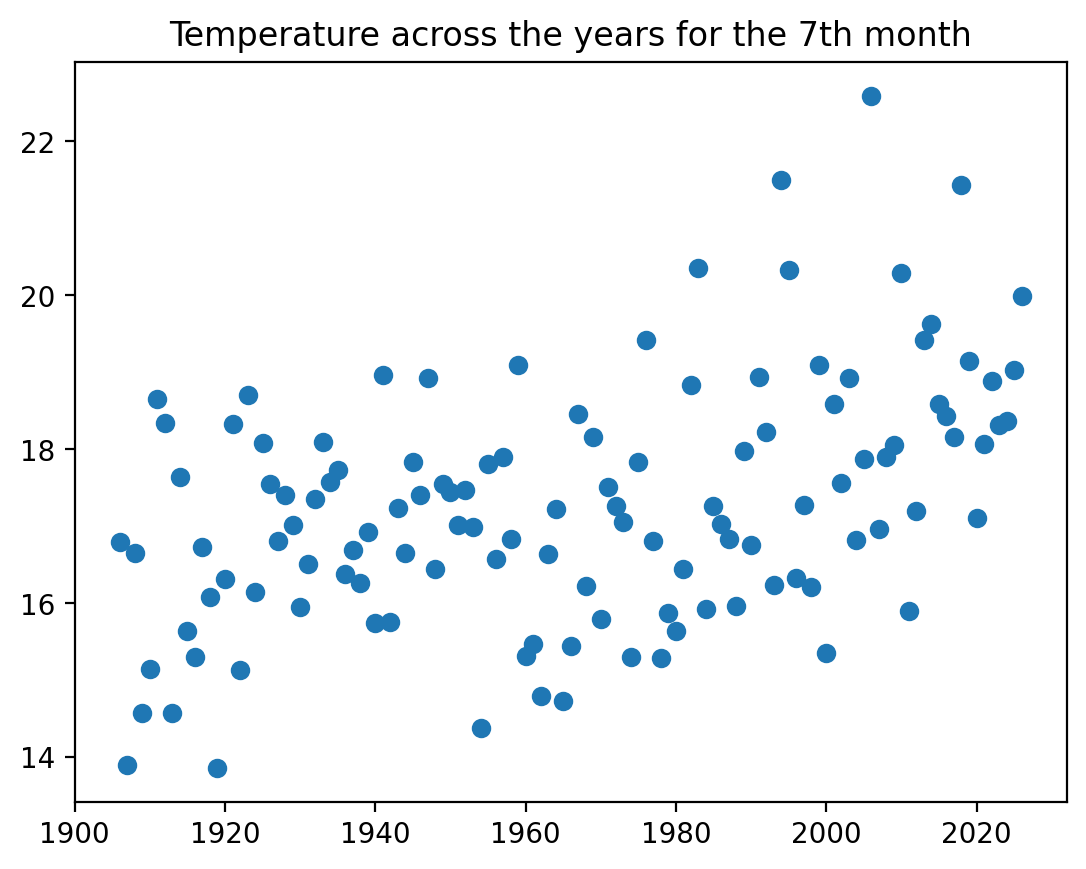

In [130]:
month = 7

plt.scatter(df['years'].values, df[month].values)
plt.title(f'Temperature across the years for the {month}th month')

Text(0, 0.5, 'temperature (celcius)')

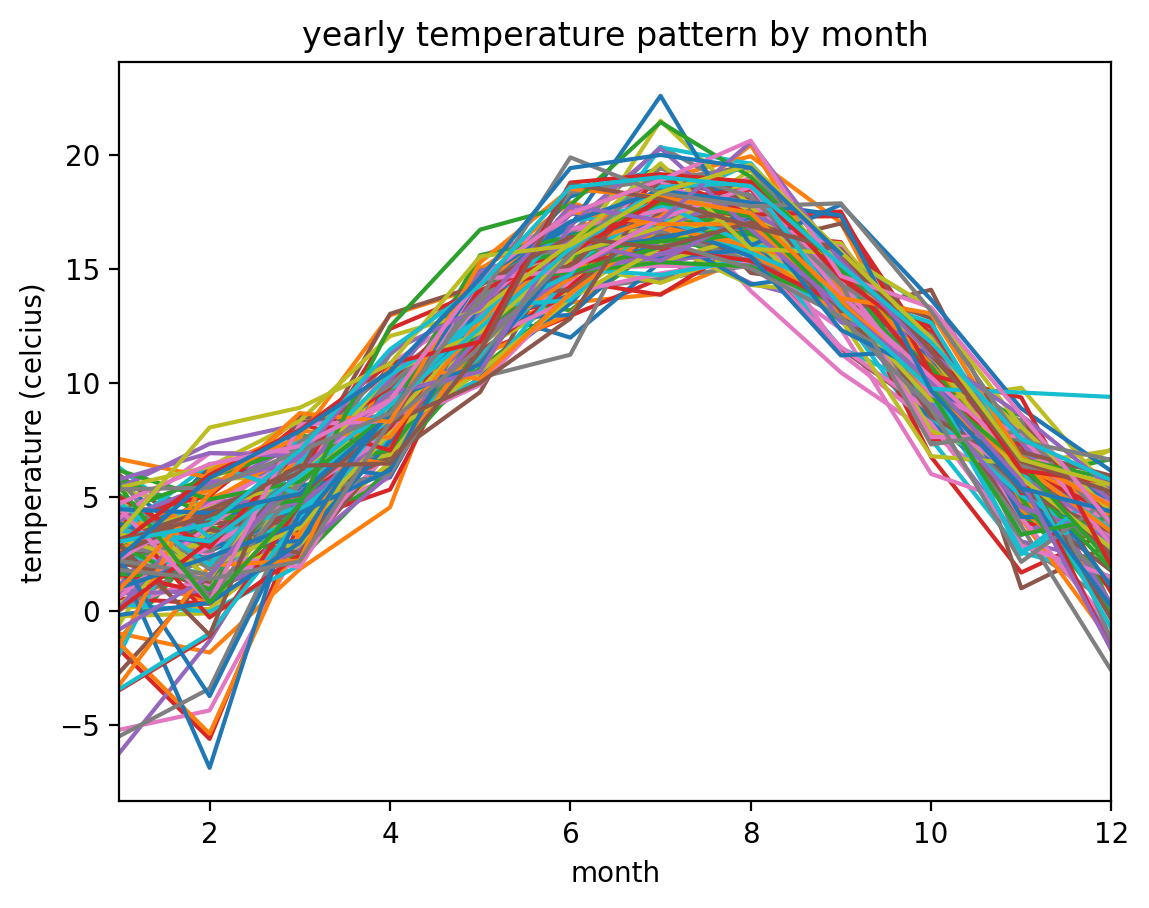

In [131]:
plt.plot(df.set_index('years').T)
plt.title('yearly temperature pattern by month')
plt.xlim((1,12))
plt.xlabel('month')
plt.ylabel('temperature (celcius)')

## Mapping 

In [ ]:
# Function taken from sonification tutorial 
def map_value(value, min_value, max_value, min_result, max_result):
    '''maps value (or array of values) from one range to another'''
 
    result = min_result + (value - min_value)/(max_value - min_value)*(max_result - min_result)
    return result

In [133]:
map_value(5, 1, 10, 10, 20)

14.444444444444445

In [ ]:
def expand_scale(notes, octaves=range(1, 7)):
    return [f"{note}{octave}" for octave in octaves for note in notes]

# Define major / major-type scales
c_major = expand_scale(["C", "D", "E", "F", "G", "A", "B"])
c_pentatonic = expand_scale(["C", "D", "E", "G", "A"])
c_lydian = expand_scale(["C", "D", "E", "F#", "G", "A", "B"])
c_mixolydian = expand_scale(["C", "D", "E", "F", "G", "A", "Bb"])

# Define minor / minor-type scales
c_natural_minor = expand_scale(["C", "D", "Eb", "F", "G", "Ab", "Bb"])
c_minor_pentatonic = expand_scale(["C", "Eb", "F", "G", "Bb"])
c_minor_blues = expand_scale(["C", "Eb", "F", "Gb", "G", "Bb"])
c_dorian = expand_scale(["C", "D", "Eb", "F", "G", "A", "Bb"])
c_harmonic_minor = expand_scale(["C", "D", "Eb", "F", "G", "Ab", "B"])
c_melodic_minor = expand_scale(["C", "D", "Eb", "F", "G", "A", "B"])
c_phrygian = expand_scale(["C", "Db", "Eb", "F", "G", "Ab", "Bb"])

note_names = c_lydian
midi_notes = (str2midi(n) for n in note_names)
midi_notes = list(midi_notes)
n_notes = len(note_names)

t_notes = [note.Note(n) for n in note_names]
stream_ = stream.Stream(t_notes)
stream_.show('midi', autoplay=True)


In [135]:
n_notes

42

In [136]:
len(midi_notes)

42

1440 datapoints mapped to a certain number of notes 

let's look at our temperature range to see how the mapping would look 

In [137]:
mins = []
maxs = []

for year in range(1906, 2027):
    temps = df[df['years']==year].values
    # print((temps[0][1:]))     # temp is (1,13) dimensional array, so we 
    mins.append(min(temps[0][1:]))
    maxs.append(max(temps[0][1:]))

print(len(mins), len(maxs))

print(min(mins), max(maxs))

temp_range = max(maxs) - min(mins)
print(temp_range)

121 121
-6.9 22.59
29.490000000000002


Part to calculate yearly average temperature to make a bassline 

In [138]:
yearly_avg = df.drop(columns='years').mean(axis=1).round()
yearly_avg_df = pd.DataFrame({'year': df['years'], 'average_temperature': yearly_avg})
print(yearly_avg_df.to_string(index=False))
print(f"Rounded yearly-average range: {int(yearly_avg.min())} to {int(yearly_avg.max())} °C")

 year  average_temperature
 1906                  9.0
 1907                  9.0
 1908                  8.0
 1909                  8.0
 1910                  9.0
 1911                 10.0
 1912                  9.0
 1913                 10.0
 1914                 10.0
 1915                  9.0
 1916                  9.0
 1917                  8.0
 1918                  9.0
 1919                  8.0
 1920                  9.0
 1921                 10.0
 1922                  8.0
 1923                  9.0
 1924                  8.0
 1925                  9.0
 1926                 10.0
 1927                  9.0
 1928                  9.0
 1929                  8.0
 1930                 10.0
 1931                  9.0
 1932                  9.0
 1933                  9.0
 1934                 10.0
 1935                 10.0
 1936                  9.0
 1937                  9.0
 1938                 10.0
 1939                 10.0
 1940                  8.0
 1941                  9.0
 

the range of temepratures in our data is 29, from -6.9 to 22.59. if we wanna map each value between -6.9 and 22.59 to a note maybe it makes sense to round all of the temperatures to the nearest whole number so that we don't need to account for all of the decimal numbers in the data.

maybe it then also makes sense to extend our note list to also have 29 notes. so that the mapping is 1-to-1 between the notes and the temperatures. then the increase in temperature will also match the increase in the octaves? 

### creating a new dataframe for the processed temperature data: rounding the temperature values 

In [139]:
processed_df = (df.round())
long_proc_df = processed_df.melt(id_vars='years', var_name="month", value_name='temperature')
long_proc_df['date'] = pd.to_datetime(long_proc_df[['years', 'month']].assign(day=1))
long_proc_df = long_proc_df.sort_values('date')
long_proc_df

,years,month,temperature,date
0,1906,1,3.0,1906-01-01
121,1906,2,2.0,1906-02-01
242,1906,3,4.0,1906-03-01
363,1906,4,8.0,1906-04-01
484,1906,5,12.0,1906-05-01
...,...,...,...,...
967,2026,8,19.0,2026-08-01
1088,2026,9,16.0,2026-09-01
1209,2026,10,NaN,2026-10-01
1330,2026,11,NaN,2026-11-01


In [140]:
temps = np.array(long_proc_df['temperature'])
temps


array([ 3.,  2.,  4., ..., nan, nan, nan])

In [141]:
max_temp = max(temps)
min_temp = min(temps)
range_temp = max_temp - min_temp
print(max_temp, min_temp, range_temp)


max_midi = max(midi_notes)
min_midi = min(midi_notes)
range_midi = max_midi - min_midi


print(max_midi, min_midi, range_midi)

23.0 -7.0 30.0
95 24 71


# Mapping Prototype !!! give it a listen

the piano keys that give the sound are temporary, i will try to figure out a way to change the sound output and maybe speed it up.

also can someone lmk if the c lydian scale i added is correct? its defined above lmk. i did like 4 octaves to account for the range of 30 temperatures we had but it also doesn't sound super duper nice. 

In [ ]:
# Sample every quarter year and map to midi notes 
sampled_temps = temps[::3]  
sampled_temps = sampled_temps[~np.isnan(sampled_temps)]
scale_indices = np.rint(map_value(sampled_temps, min_temp, max_temp, 0, len(midi_notes) - 1)).astype(int)
mapped_temps = np.array(midi_notes)[scale_indices]  

# Map yearly average temperatures to bassline notes 
yearly_avg_values = yearly_avg_df['average_temperature'].to_numpy() # Average yearly temperature as bassline
melody_pitch_classes = {int(midi) % 12 for midi in midi_notes}
minor_third = str2midi('Eb3') % 12
bassline_pitch_names = ['C', 'Eb', 'F', 'G'] if minor_third in melody_pitch_classes else ['C', 'D', 'E', 'G', 'A']
bassline_octaves = range(3, 5)
bassline_midi_notes = np.array([
    str2midi(f'{pitch}{octave}')
    for octave in bassline_octaves
    for pitch in bassline_pitch_names
])
min_yearly_temp = np.nanmin(yearly_avg_values)
max_yearly_temp = np.nanmax(yearly_avg_values)
if min_yearly_temp == max_yearly_temp:
    bassline_midis = np.full(len(yearly_avg_values), bassline_midi_notes[len(bassline_midi_notes) // 2], dtype=int)
else:
    bassline_indices = np.rint(map_value(
        yearly_avg_values, min_yearly_temp, max_yearly_temp, 0, len(bassline_midi_notes) - 1
    )).astype(int)
    bassline_midis = bassline_midi_notes[bassline_indices]
bass_positions = np.arange(0, len(mapped_temps), 4)  

# Pick instruments for melody and bassline 
melody = stream.Part()
melody.insert(0, instrument.Marimba())
bassline = stream.Part()
bassline.insert(0, instrument.Bassoon())

# Play the melodies 
for i, midi_value in enumerate(mapped_temps):
    melody.insert(i, note.Note(int(midi_value)))

for year_index, position in enumerate(bass_positions):
    bassline.insert(int(position), note.Note(int(bassline_midis[year_index])))

stream_ = stream.Score()
stream_.insert(0, melody)
stream_.insert(0, bassline)
stream_.show('midi', autoplay=True)

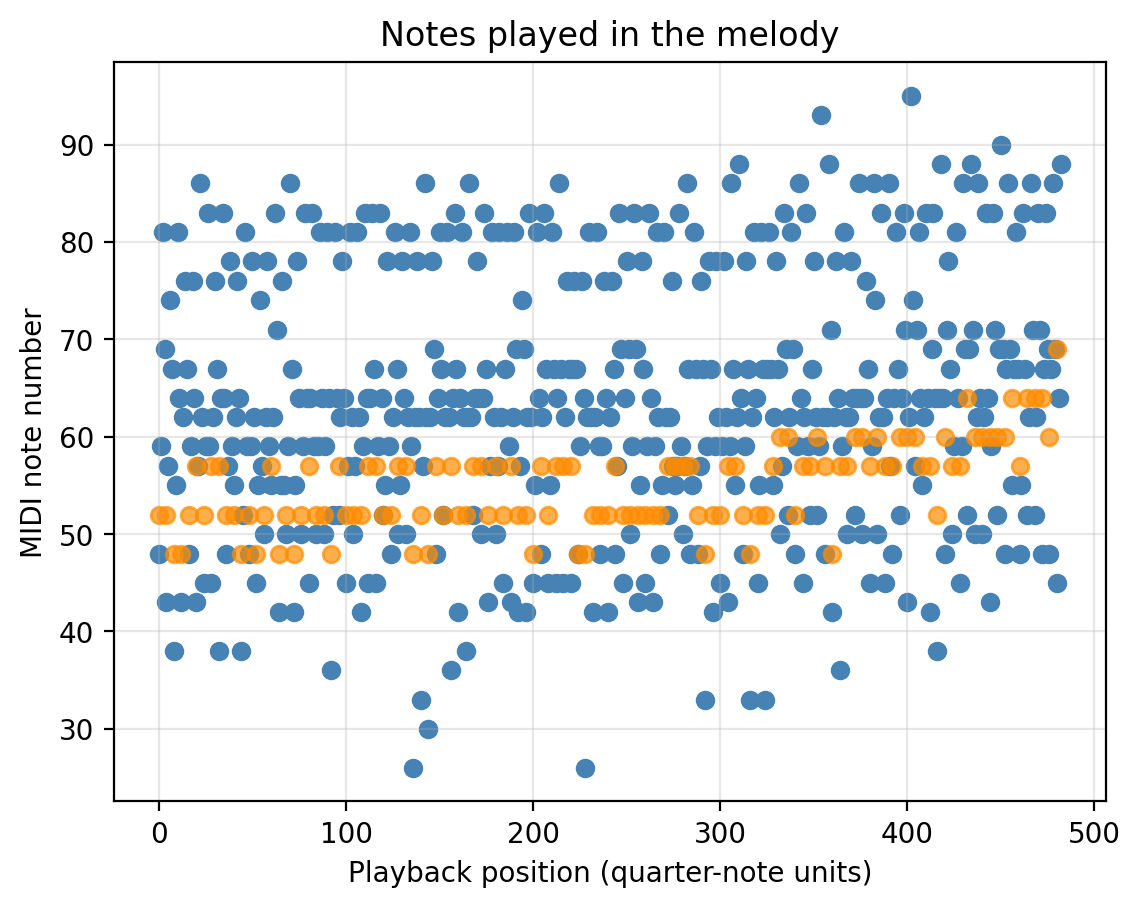

In [ ]:
# Plot the melody and bassnotes in a scatterplot for visualisation 
played_melody_notes = list(melody.recurse().getElementsByClass(note.Note))
melody_offsets = [n.getOffsetInHierarchy(melody) for n in played_melody_notes]
melody_pitches = [n.pitch.midi for n in played_melody_notes]

plt.scatter(melody_offsets, melody_pitches, color='steelblue')
plt.scatter(bass_positions, bassline_midis, color='darkorange', alpha=0.7, label='baseline notes')
plt.title('Notes played in the melody')
plt.xlabel('Playback position (quarter-note units)')
plt.ylabel('MIDI note number')
plt.grid(True, alpha=0.3)

In [ ]:
# Animate a marker across the monthly temperature dataset
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

animation_dates = long_proc_df['date'].to_numpy()
animation_temps = long_proc_df['temperature'].to_numpy()
animation_frames = np.unique(np.linspace(
    0, len(animation_temps) - 1, min(len(animation_temps), 240), dtype=int
))

animation_fig, animation_ax = plt.subplots(figsize=(12, 5))
animation_ax.plot(animation_dates, animation_temps, color='lightgray', linewidth=1, label='All temperatures')
progress_line, = animation_ax.plot([], [], color='steelblue', linewidth=1.5)
current_dot, = animation_ax.plot([], [], 'o', color='darkorange', markersize=9)
current_reading = animation_ax.text(0.02, 0.95, '', transform=animation_ax.transAxes, va='top')
animation_ax.set_title('Monthly temperatures over time')
animation_ax.set_xlabel('Year')
animation_ax.set_ylabel('Temperature (°C)')
animation_ax.grid(True, alpha=0.3)
animation_ax.legend(loc='lower right')

def update_temperature_frame(frame):
    progress_line.set_data(animation_dates[:frame + 1], animation_temps[:frame + 1])
    current_dot.set_data([animation_dates[frame]], [animation_temps[frame]])
    current_reading.set_text(
        f"{pd.Timestamp(animation_dates[frame]):%Y-%m}: {animation_temps[frame]:.0f} °C"
    )
    return progress_line, current_dot, current_reading

temperature_animation = FuncAnimation(
    animation_fig, update_temperature_frame, frames=animation_frames,
    interval=60, blit=True, repeat=True
)
display(HTML(temperature_animation.to_jshtml()))
plt.close(animation_fig)